<a href="https://www.kaggle.com/code/nicolasfalcone/summit-2026-anemia-gustavo-e-falcone?scriptVersionId=361702882" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Summit 2026 | Classificação de Anemia com SVM

**Turma:** 6B  
**Integrantes:** Nicolas Falcone e Gustavo Palmeira de Jesus Junior

---

Este projeto utiliza **Support Vector Machine (SVM)** para classificar registros do hemograma em categorias de diagnóstico presentes no conjunto de dados. O fluxo inclui exploração, preparação dos dados, seleção de hiperparâmetros e avaliação do modelo.

## 1. Importação e carregamento

O código procura o CSV no ambiente Kaggle. Se não o encontrar, permite selecionar o arquivo em uma sessão do Google Colab. O idioma dos rótulos dos resultados é definido na célula **Configuração de idioma**.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

arquivo = Path(
    "/kaggle/input/datasets/ehababoelnaga/anemia-types-classification/diagnosed_cbc_data_v4.csv"
)

if not arquivo.exists():
    encontrados = list(Path("/kaggle/input").rglob("diagnosed_cbc_data_v4.csv"))
    if encontrados:
        arquivo = encontrados[0]

if arquivo.exists():
    df = pd.read_csv(arquivo)
else:
    try:
        from google.colab import files
        arquivos_enviados = files.upload()
        nome_arquivo = next(iter(arquivos_enviados))
        df = pd.read_csv(nome_arquivo)
    except ImportError as erro:
        raise FileNotFoundError(
            "CSV não encontrado. Disponibilize diagnosed_cbc_data_v4.csv no ambiente."
        ) from erro

print(f"Dataset carregado: {df.shape[0]} registros e {df.shape[1]} colunas.")

Dataset carregado: 1281 registros e 15 colunas.


## 2. Configuração de idioma

Definimos os nomes das classes mapeando tanto os textos originais em inglês quanto os possíveis números da codificação.

In [2]:
# Mapeamento robusto cobrindo textos em inglês e números codificados
MAPA_DIAGNOSTICOS = {
    "Healthy": "Saudável",
    "Iron deficiency anemia": "Anemia por deficiência de ferro",
    "Leukemia": "Leucemia",
    "Leukemia with thrombocytopenia": "Leucemia com trombocitopenia",
    "Macrocytic anemia": "Anemia macrocítica",
    "Normocytic hypochromic anemia": "Anemia normocítica hipocrômica",
    "Normocytic normochromic anemia": "Anemia normocítica normocrômica",
    "Other microcytic anemia": "Outra anemia microcítica",
    "Thrombocytopenia": "Trombocitopenia",
    0: "Saudável",
    1: "Anemia por deficiência de ferro",
    2: "Leucemia",
    3: "Leucemia com trombocitopenia",
    4: "Anemia macrocítica",
    5: "Anemia normocítica hipocrômica",
    6: "Anemia normocítica normocrômica",
    7: "Outra anemia microcítica",
    8: "Trombocitopenia",
    "0": "Saudável",
    "1": "Anemia por deficiência de ferro",
    "2": "Leucemia",
    "3": "Leucemia com trombocitopenia",
    "4": "Anemia macrocítica",
    "5": "Anemia normocítica hipocrômica",
    "6": "Anemia normocítica normocrômica",
    "7": "Outra anemia microcítica",
    "8": "Trombocitopenia"
}

TEXTO = {
    "coluna_diagnostico": "Diagnóstico",
    "quantidade": "Quantidade",
    "classe": "Classe",
    "precisao": "Precisão",
    "revocacao": "Revocação",
    "f1": "F1-score",
    "amostras": "Amostras",
    "acuracia": "Acurácia",
    "acuracia_teste": "Acurácia no conjunto de teste",
    "relatorio": "Relatório de classificação",
    "media_macro": "Média macro",
    "media_ponderada": "Média ponderada",
    "matriz_titulo": "Matriz de Confusão — SVM",
    "previsto": "Diagnóstico previsto",
    "real": "Diagnóstico real",
    "idioma": "Português",
}

def traduzir_diagnostico(nome):
    """Retorna o nome do diagnóstico em português."""
    return MAPA_DIAGNOSTICOS.get(nome, str(nome))

print(f"Idioma dos resultados: {TEXTO['idioma']}")

Idioma dos resultados: Português


## 3. Exploração inicial

Visualizamos algumas linhas, os tipos de dados e a quantidade de valores ausentes antes do treinamento.

In [3]:
amostra = df.head().rename(columns={"Diagnosis": TEXTO["coluna_diagnostico"]})
amostra[TEXTO["coluna_diagnostico"]] = amostra[TEXTO["coluna_diagnostico"]].map(traduzir_diagnostico)
display(amostra)

print("\nInformações do dataset:")
df.info()

print("\nValores ausentes por coluna:")
display(df.isna().sum().rename("Valores ausentes").to_frame())

,WBC,LYMp,NEUTp,LYMn,NEUTn,RBC,HGB,HCT,MCV,MCH,MCHC,PLT,PDW,PCT,Diagnóstico
0,10.0,43.2,50.1,4.3,5.0,2.77,7.3,24.2,87.7,26.3,30.1,189.0,12.5,0.17,Anemia normocítica hipocrômica
1,10.0,42.4,52.3,4.2,5.3,2.84,7.3,25.0,88.2,25.7,20.2,180.0,12.5,0.16,Anemia normocítica hipocrômica
2,7.2,30.7,60.7,2.2,4.4,3.97,9.0,30.5,77.0,22.6,29.5,148.0,14.3,0.14,Anemia por deficiência de ferro
3,6.0,30.2,63.5,1.8,3.8,4.22,3.8,32.8,77.9,23.2,29.8,143.0,11.3,0.12,Anemia por deficiência de ferro
4,4.2,39.1,53.7,1.6,2.3,3.93,0.4,316.0,80.6,23.9,29.7,236.0,12.8,0.22,Anemia normocítica hipocrômica



Informações do dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1281 entries, 0 to 1280
Data columns (total 15 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   WBC        1281 non-null   float64
 1   LYMp       1281 non-null   float64
 2   NEUTp      1281 non-null   float64
 3   LYMn       1281 non-null   float64
 4   NEUTn      1281 non-null   float64
 5   RBC        1281 non-null   float64
 6   HGB        1281 non-null   float64
 7   HCT        1281 non-null   float64
 8   MCV        1281 non-null   float64
 9   MCH        1281 non-null   float64
 10  MCHC       1281 non-null   float64
 11  PLT        1281 non-null   float64
 12  PDW        1281 non-null   float64
 13  PCT        1281 non-null   float64
 14  Diagnosis  1281 non-null   object 
dtypes: float64(14), object(1)
memory usage: 150.2+ KB

Valores ausentes por coluna:


,Valores ausentes
WBC,0
LYMp,0
NEUTp,0
LYMn,0
NEUTn,0
RBC,0
HGB,0
HCT,0
MCV,0
MCH,0


## 4. Preparação dos dados

Removemos registros duplicados e linhas sem o diagnóstico. A imputação de valores numéricos e a padronização ficam dentro do *Pipeline*, sendo ajustadas somente com os dados de treino em cada etapa da validação cruzada.

In [4]:
X = df.drop(columns=["Diagnosis"])
y = df["Diagnosis"]

print(f"Registros após a limpeza: {len(df)}")
print(f"Quantidade de classes: {y.nunique()}")

contagem_classes = y.value_counts()
contagem_classes.index = contagem_classes.index.map(traduzir_diagnostico)
display(
    contagem_classes
    .rename_axis(TEXTO["coluna_diagnostico"])
    .to_frame(TEXTO["quantidade"])
)

Registros após a limpeza: 1281
Quantidade de classes: 9


,Quantidade
Diagnóstico,
Saudável,336
Anemia normocítica hipocrômica,279
Anemia normocítica normocrômica,269
Anemia por deficiência de ferro,189
Trombocitopenia,73
Outra anemia microcítica,59
Leucemia,47
Anemia macrocítica,18
Leucemia com trombocitopenia,11


## 5. Treinamento e ajuste do SVM

Separamos 80% dos dados para treino e 20% para teste, mantendo a proporção das classes. O `GridSearchCV` compara combinações de kernel e hiperparâmetros usando o **F1-score macro**, que dá o mesmo peso a cada classe.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

pipeline = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("padronizador", StandardScaler()),
    ("svm", SVC())
])

parametros = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.01, 0.1, 1],
    "svm__kernel": ["rbf", "linear"]
}

busca = GridSearchCV(
    pipeline,
    parametros,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

busca.fit(X_train, y_train)

print("Melhores parâmetros:", busca.best_params_)
print(f"Melhor F1 macro na validação cruzada: {busca.best_score_:.4f}")

Melhores parâmetros: {'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Melhor F1 macro na validação cruzada: 0.7999


## 6. Avaliação do modelo

A avaliação final é realizada no conjunto de teste, que não participa da seleção dos hiperparâmetros. O relatório apresenta as métricas por classe, a matriz de confusão e o F1-score por classe.

Acurácia no conjunto de teste: 85.99%

Relatório de classificação:


,Precisão,Revocação,F1-score,Amostras
Classe,,,,
Saudável,0.912,0.925,0.919,67
Anemia por deficiência de ferro,0.919,0.895,0.907,38
Leucemia,0.500,0.444,0.471,9
Leucemia com trombocitopenia,1.000,0.500,0.667,2
Anemia macrocítica,1.000,0.750,0.857,4
Anemia normocítica hipocrômica,0.776,0.804,0.789,56
Anemia normocítica normocrômica,0.895,0.944,0.919,54
Outra anemia microcítica,0.800,0.667,0.727,12
Trombocitopenia,0.867,0.867,0.867,15


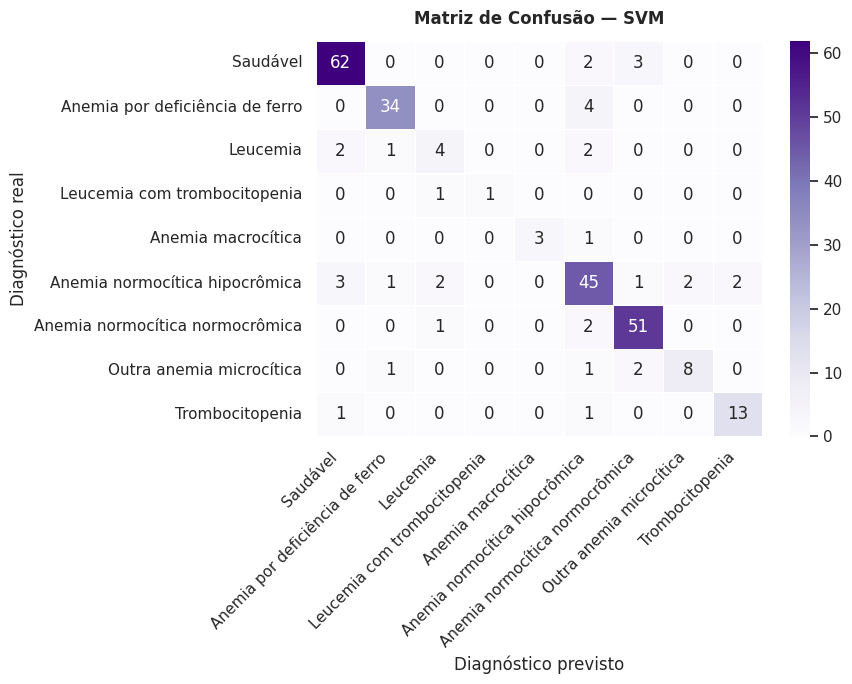

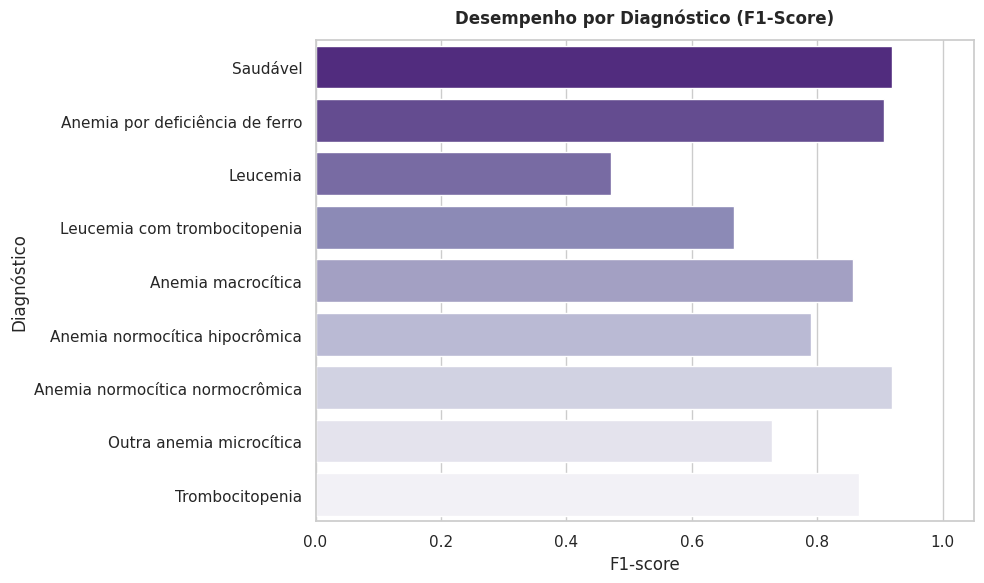

In [6]:
# Faz a previsão com o modelo treinado
y_pred = busca.predict(X_test)

# Calcula e exibe a acurácia
acuracia = accuracy_score(y_test, y_pred) * 100
print(f"{TEXTO['acuracia_teste']}: {acuracia:.2f}%")

# Extrai as classes e aplica a tradução (funciona tanto para números quanto para textos em inglês)
classes = busca.classes_
nomes_classes = [traduzir_diagnostico(classe) for classe in classes]

# Gera o relatório de classificação
relatorio = classification_report(
    y_test,
    y_pred,
    labels=classes,
    target_names=nomes_classes,
    output_dict=True,
    zero_division=0
)

# Formata o relatório para exibição em DataFrame
linhas_relatorio = []
for nome_classe in nomes_classes:
    metricas = relatorio[nome_classe]
    linhas_relatorio.append({
        TEXTO["classe"]: nome_classe,
        TEXTO["precisao"]: metricas["precision"],
        TEXTO["revocacao"]: metricas["recall"],
        TEXTO["f1"]: metricas["f1-score"],
        TEXTO["amostras"]: int(metricas["support"]),
    })

# Adiciona as médias (macro e ponderada)
for chave, rotulo in [
    ("macro avg", TEXTO["media_macro"]),
    ("weighted avg", TEXTO["media_ponderada"]),
]:
    metricas = relatorio[chave]
    linhas_relatorio.append({
        TEXTO["classe"]: rotulo,
        TEXTO["precisao"]: metricas["precision"],
        TEXTO["revocacao"]: metricas["recall"],
        TEXTO["f1"]: metricas["f1-score"],
        TEXTO["amostras"]: int(metricas["support"]),
    })

# Exibe a tabela formatada
print(f"\n{TEXTO['relatorio']}:")
display(pd.DataFrame(linhas_relatorio).set_index(TEXTO["classe"]).round(3))

# Cria a matriz de confusão
matriz = confusion_matrix(y_test, y_pred, labels=classes)

# Plota a matriz com o Seaborn
plt.figure(figsize=(9, 7))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=nomes_classes,
    yticklabels=nomes_classes,
    linewidths=0.5,
    linecolor="white"
)
plt.title(TEXTO["matriz_titulo"], pad=12, weight="bold")
plt.xlabel(TEXTO["previsto"])
plt.ylabel(TEXTO["real"])
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Extrai as classes e métricas ignorando as duas últimas linhas (que são as médias)
classes_plot = [linha[TEXTO["classe"]] for linha in linhas_relatorio[:-2]]
f1_plot = [linha[TEXTO["f1"]] for linha in linhas_relatorio[:-2]]

# Plota o gráfico de barras horizontais
plt.figure(figsize=(10, 6))
sns.barplot(x=f1_plot, y=classes_plot, palette="Purples_r", hue=classes_plot, legend=False)
plt.title("Desempenho por Diagnóstico (F1-Score)", pad=12, weight="bold")
plt.xlabel(TEXTO["f1"])
plt.ylabel(TEXTO["coluna_diagnostico"])
plt.xlim(0, 1.05) # O F1-score varia entre 0 e 1
plt.tight_layout()
plt.show()